# TKT4108 Structural Dynamics 2

## Solution exercise 9

**Main topics:**  Estimation of spectra

**References:** Github examples, lecture notes



### Problem 1

**a)**

The auto spectral density of the response is defined by

$$S_y(\omega) = |H(\omega) |^2 S_x(\omega)$$

The standard deviation is the square root of the auto spectral density integral:

$$ \sigma_y = \sqrt{ \int_0^{\infty}{S_y(\omega)} d\omega } $$

The supplied spectrum is one-sided. Displacement spectra have units $\mathrm{m^2\,s/rad}$, and the standard deviation has units m.


(0.0, 20.0)

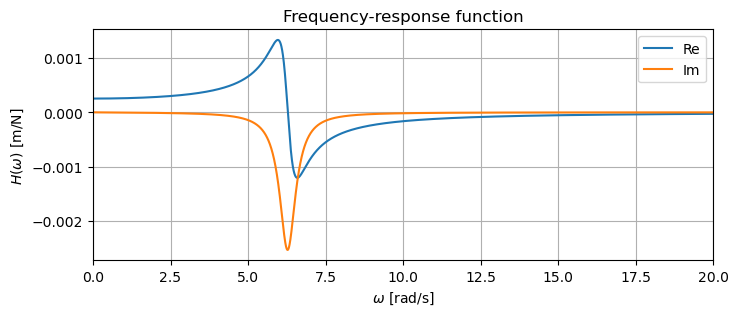

In [2]:
import numpy as np
from matplotlib import pyplot as plt
from scipy import signal as spsi

import sys
sys.path.append('./../../modules')
from time_integration import * # Import all functions in the module time_integration

fn = 1
xi = 5/100
omegan = 2*np.pi*fn
ms = 100
ks = omegan**2*ms

cs = 2*xi*ms*omegan

omega_axis = np.linspace(0,50,10001)

H = 1/(-omega_axis**2*ms + 1j*omega_axis*cs + ks) # Frequency response function

plt.figure(figsize=(8,3))
plt.plot(omega_axis,np.real(H),label='Re')
plt.plot(omega_axis,np.imag(H),label='Im')
plt.xlabel(r'$\omega$ [rad/s]')
plt.ylabel(r'$H(\omega)$ [m/N]')
plt.title('Frequency-response function')
plt.grid()
plt.legend()
plt.xlim(0,20)

(0.0, 40.0)

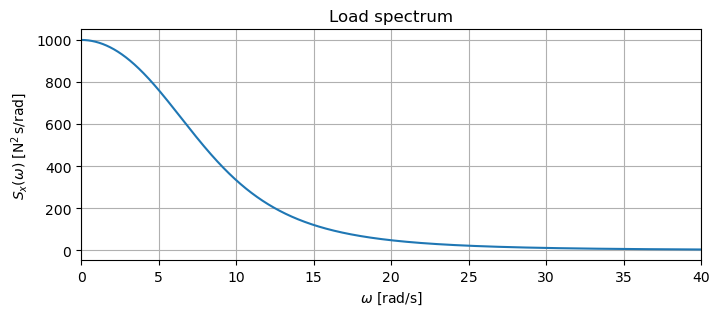

In [3]:
Sx = 1e3/(1+0.01*omega_axis**2+0.0001*omega_axis**4)

plt.figure(figsize=(8,3))
plt.plot(omega_axis,Sx)
plt.xlabel(r'$\omega$ [rad/s]')
plt.ylabel(r'$S_x(\omega)$ [$\mathrm{N^2\,s/rad}$]')
plt.grid()
plt.title('Load spectrum')
plt.xlim(0,40)

Response standard deviation = 0.064675 m


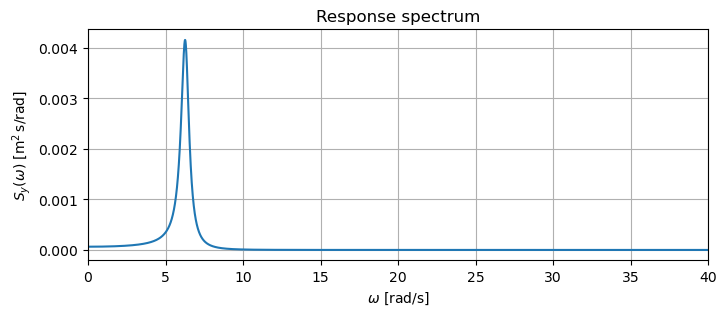

In [4]:
Sy = np.abs(H)**2*Sx

plt.figure(figsize=(8,3))
plt.plot(omega_axis,Sy)
plt.xlabel(r'$\omega$ [rad/s]')
plt.ylabel(r'$S_y(\omega)$ [$\mathrm{m^2\,s/rad}$]')
plt.grid()
plt.title('Response spectrum')
plt.xlim(0,40)

from scipy.integrate import quad

def response_psd(omega):
    load_psd = 1e3/(1 + 0.01*omega**2 + 0.0001*omega**4)
    return load_psd / ((ks - ms*omega**2)**2 + (cs*omega)**2)

variance_y, _ = quad(response_psd, 0, np.inf)
sigma_y = np.sqrt(variance_y)
print(f"Response standard deviation = {sigma_y:.6f} m")


**b)**

The natural frequency is 1 Hz, so the period is 1 s. We choose a time step close to $0.02$ s, giving approximately 50 points per vibration cycle.

We use the IFFT-based simulation method. We choose an odd sample count ($N$).

$$A_k=\sqrt{2S_x(\omega_k)\Delta\omega},\qquad
X_k=\frac{A_k}{2}e^{i\phi_k},\qquad
x_n=N\operatorname{IRFFT}(X_k).$$


(0.0, 600.02)

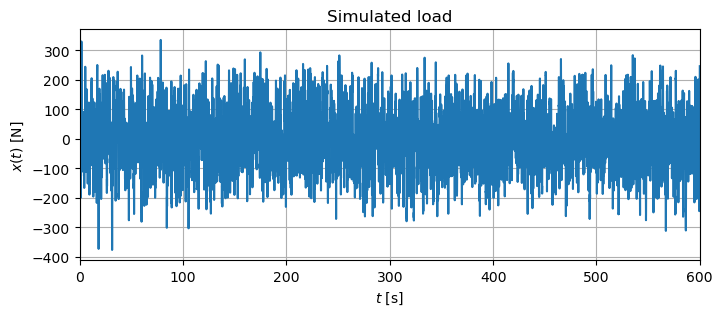

In [5]:
dt=0.02

T=600.02 # Odd number of samples

N=int(round(T/dt))

t=np.arange(0,N,1)*dt # Time axis

domega=2*np.pi/T # Frequency spacing

n_freq = (N + 1)//2
omega_sim = np.arange(n_freq)*domega # Nonnegative frequencies [rad/s]

Sx = 1e3/(1+0.01*omega_sim**2+0.0001*omega_sim**4)

# Generate load
phi = np.random.uniform(0, 2*np.pi, n_freq) # Random phase angles 
c = 0.5*np.sqrt(2*Sx*domega)*np.exp(1j*phi) # The complex amplitude including the phase angle
c[0] = 0.0 # Zero DC coefficient, as in Example 3.6
x = N*np.fft.irfft(c, n=N) # IRFFT with course normalization

plt.figure(figsize=(8,3))
plt.plot(t,x)
plt.xlabel('$t$ [s]')
plt.ylabel('$x(t)$ [N]')
plt.grid()
plt.title('Simulated load')
plt.xlim(0,T)


Response by Newmark's method

Simulated response standard deviation = 0.064596 m
Spectral response standard deviation = 0.064675 m


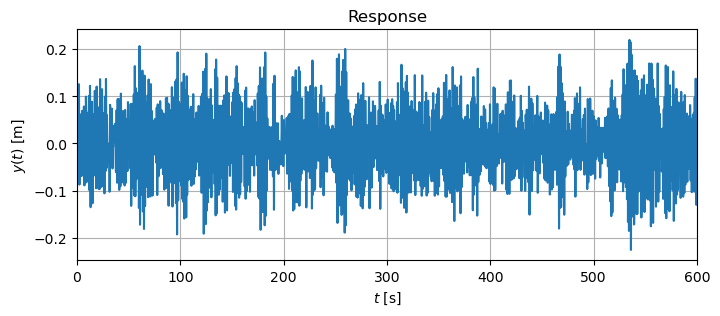

In [6]:
u0 = 0.0
udot0 = 0.0

y, _,_ = linear_newmark_krenk(ms,cs,ks,x,u0,udot0,dt)

plt.figure(figsize=(8,3))
plt.plot(t,y[0,:])
plt.xlabel('$t$ [s]')
plt.ylabel('$y(t)$ [m]')
plt.grid()
plt.title('Response')
plt.xlim(0,T)

print(f"Simulated response standard deviation = {np.std(y[0, :]):.6f} m")
print(f"Spectral response standard deviation = {sigma_y:.6f} m")


**c**)

The auto-spectral density can be estimated as follows:

 $$ S_{x}(f_k)  = \lim_{T\rightarrow \infty} \text{E} [ \: T \cdot X_k \bar{X}_k \: ]  $$

$X_k$ is the discrete Fourier transform, which is two-sided (goes from $-f_s/2$ to $f_s/2$). To get a one-sided spectrum, we must multiply by 2.

In addition, $S_{x}(f_k)$ is a spectrum as a function of $f$ (Hz). To get $S_{x}(\omega)$, we must scale by $2 \pi$:

$$ S_{x}(\omega)=S_{x}(f) /(2 \pi) $$



(0.0, 20.0)

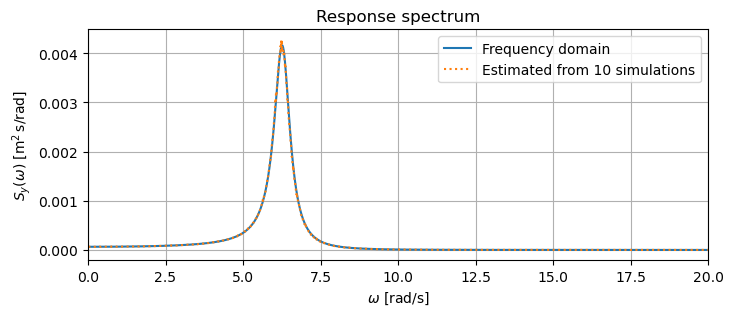

In [7]:

Nsim = 10
Sy_est_twosided_mean = np.zeros(len(t))

for k in range(Nsim): # Repeat simulation 10 times, each time with a new load time history
    
    # Generate load
    phi = np.random.uniform(0, 2*np.pi, n_freq) # Random phase angles 
    c = 0.5*np.sqrt(2*Sx*domega)*np.exp(1j*phi) # The complex amplitude including the phase angle
    c[0] = 0.0 # Zero DC coefficient, as in Example 3.6
    x = N*np.fft.irfft(c, n=N) # IRFFT with course normalization

    u0 = 0.0
    udot0 = 0.0
    
    y, _,_ = linear_newmark_krenk(ms,cs,ks,x,u0,udot0,dt)

    Y_fft = np.fft.fft(y)/N
    Y_fft = np.fft.fftshift(Y_fft) # Shift elements in vector, goes from [-omega,...,0,...+omega]

    f_fft = np.fft.fftfreq(N, d=dt) # Frequency axis in Hz
    f_fft_shift = np.fft.fftshift(f_fft)

    Sy_est_twosided=T*np.real(np.multiply(Y_fft,np.conj(Y_fft))) # Estimate spectrum (two-sided and function of Hz)
    
    Sy_est_twosided_mean = Sy_est_twosided_mean + Sy_est_twosided

Sy_est_twosided_mean = Sy_est_twosided_mean/Nsim

omega_est=f_fft_shift[f_fft_shift>0]*2*np.pi
Sy_est_mean=Sy_est_twosided_mean[0,f_fft_shift>0]/(2*np.pi)*2
    
# Plot and compare with exact solution
plt.figure(figsize=(8,3))
plt.plot(omega_axis,Sy ,label = 'Frequency domain',color='C0') 
plt.plot(omega_est,Sy_est_mean,':' ,label = 'Estimated from ' + str(Nsim) +' simulations' ,color='C1') 
plt.xlabel(r'$\omega$ [rad/s]')
plt.ylabel(r'$S_y(\omega)$ [$\mathrm{m^2\,s/rad}$]')
plt.grid()
plt.title('Response spectrum')
plt.legend()
plt.xlim(0,20)


We see that the two graphs are similar (as they should be). The estimate still has some slight noise and will fully converge as the time series becomes longer ($T\rightarrow \infty$) and the number of averages is increased ($N\rightarrow \infty$).

### Problem 2

**a**)
For an invertible modal matrix, the general reconstruction is

$$\widetilde{C}=\Phi^T C\Phi,\qquad
C=\Phi^{-T}\widetilde{C}\Phi^{-1}.$$

Here $\widetilde C_{jj}=2\xi_j\omega_j\widetilde M_{jj}$ with $\xi_j=0.02$.


In [8]:
import numpy as np
from scipy import linalg as spla

M = np.eye(5) *1000
K = np.zeros((6,6))
EI = 2.1e11*3.36e-6
L = 3
ks = 2 *12*EI/L**3

for k in range(5):
    K[k+1,k+1] = K[k+1,k+1] + ks
    K[k,k] = K[k,k] + ks
    K[k+1,k] = K[k+1,k] -ks
    K[k,k+1] = K[k,k+1] -ks

K = K[1::,1::] # Introduce boundary conditions

lam, vec = spla.eig(K,M)

indx = np.argsort(lam)
lam = lam[indx]

vec = vec[:,indx]

f = np.real(lam**0.5)/2/np.pi

M_modal = vec.T @ M @ vec

C_modal = 2*np.eye(5)*2/100*M_modal*np.diag(f)*2*np.pi

Phi_inv = np.linalg.inv(vec)
C = Phi_inv.T @ C_modal @ Phi_inv

# Verify that the target damping has been achieved by re-calculation of damping

# State-space A-matrix
A = np.block([
    [np.zeros_like(M), np.eye(M.shape[0])],
    [-np.linalg.inv(M) @ K, -np.linalg.inv(M) @ C]
])

# State-space B-matrix
B = np.block([
    [np.zeros_like(M)],
    [np.linalg.inv(M)]
])

lam,vec = np.linalg.eig(A)
f = np.abs(lam)/2/np.pi
xi = -np.real(lam)/np.abs(lam)

print('Calculated damping ratios: ')
print(xi)

print('Calculated natural frequencies [Hz]: ')
print(f)

Calculated damping ratios: 
[0.02 0.02 0.02 0.02 0.02 0.02 0.02 0.02 0.02 0.02]
Calculated natural frequencies [Hz]: 
[7.64882898 7.64882898 6.70625485 6.70625485 5.22037983 5.22037983
 3.31158068 3.31158068 1.13449696 1.13449696]


**b**)

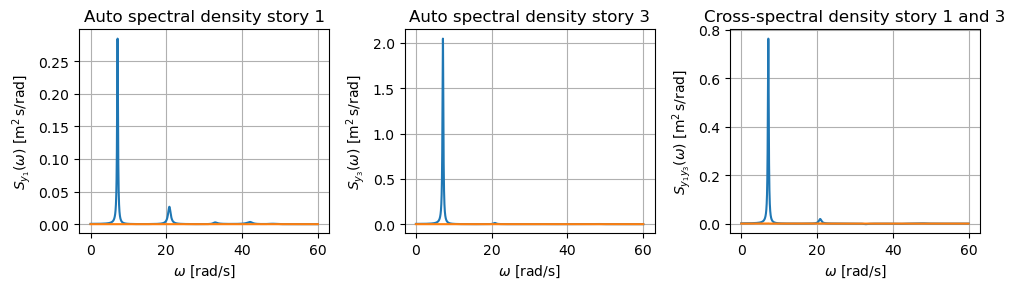

In [9]:
omega_axis = np.linspace(0,60,10000)
H = np.zeros((M.shape[0],M.shape[0],len(omega_axis)),dtype = complex)
Sx = np.zeros((M.shape[0],M.shape[0],len(omega_axis)))
Sy = np.zeros((M.shape[0],M.shape[0],len(omega_axis)),dtype = complex)

Sx[1,1,omega_axis<60] = 1e8
Sx[3,3,omega_axis<60] = 1e8

for k in range(len(omega_axis)):
    H[:,:,k] = np.linalg.inv(-omega_axis[k]**2*M + 1j*omega_axis[k]*C + K)
    Sy[:,:,k] = H[:,:,k] @ Sx[:,:,k] @ np.conj(H[:,:,k].T)
    
fig, axs = plt.subplots(1,3,figsize=(10,3))

axs[0].plot(omega_axis,np.real(Sy[0,0,:]))
axs[0].plot(omega_axis,np.imag(Sy[0,0,:]))
axs[0].set_xlabel(r"$\omega$ [rad/s]")
axs[0].set_ylabel(r"$S_{y_1}(\omega)$ [$\mathrm{m^2\,s/rad}$]")
axs[0].set_title("Auto spectral density story 1")
axs[0].grid()

axs[1].plot(omega_axis,np.real(Sy[2,2,:]))
axs[1].plot(omega_axis,np.imag(Sy[2,2,:]))
axs[1].set_xlabel(r"$\omega$ [rad/s]")
axs[1].set_ylabel(r"$S_{y_3}(\omega)$ [$\mathrm{m^2\,s/rad}$]")
axs[1].set_title("Auto spectral density story 3")
axs[1].grid()

axs[2].plot(omega_axis,np.real(Sy[0,2,:]))
axs[2].plot(omega_axis,np.imag(Sy[0,2,:]))
axs[2].set_ylabel(r"$S_{y_1 y_3}(\omega)$ [$\mathrm{m^2\,s/rad}$]")
axs[2].set_xlabel(r"$\omega$ [rad/s]")
axs[2].set_title("Cross-spectral density story 1 and 3")
axs[2].grid()

plt.tight_layout()


**c)**

We choose a time step close to $0.01$ s and use the IRFFT method from Example 3.6 for each load, with independently drawn phases.


Text(0.5, 1.0, 'Response')

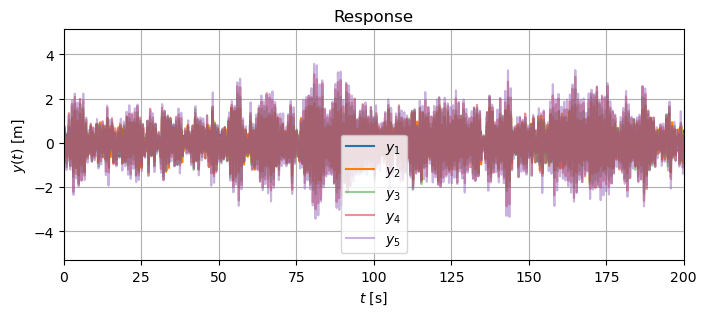

In [10]:
import scipy

dt=0.01
T=1800.01
N=int(round(T/dt))

t=np.arange(0,N,1)*dt # Time axis

domega=2*np.pi/T # Frequency spacing

n_freq = (N + 1)//2
omega_sim = np.arange(n_freq)*domega # Nonnegative frequencies [rad/s]

Sx_sim=np.zeros_like(omega_sim)
Sx_sim[omega_sim<60] = 1e8

# Generate load x2
phi = np.random.uniform(0, 2*np.pi, n_freq) # Random phase angles 
c = 0.5*np.sqrt(2*Sx_sim*domega)*np.exp(1j*phi) # The complex amplitude including the phase angle
c[0] = 0.0 # Zero DC coefficient, as in Example 3.6
x2 = N*np.fft.irfft(c, n=N) # IRFFT with course normalization

# Generate load x4
phi = np.random.uniform(0, 2*np.pi, n_freq) # Random phase angles 
c = 0.5*np.sqrt(2*Sx_sim*domega)*np.exp(1j*phi) # The complex amplitude including the phase angle
c[0] = 0.0 # Zero DC coefficient, as in Example 3.6
x4 = N*np.fft.irfft(c, n=N) # IRFFT with course normalization

x=np.zeros((5,len(t)))
x[1,:]=x2
x[3,:]=x4

# Convert state-space matrix to discrete time
A_d = scipy.linalg.expm(A * dt)
B_d = np.dot( scipy.linalg.expm(A * dt) - np.eye(A.shape[0]), np.linalg.inv(A)) @ B

x_state=np.zeros((10,len(t))) # State vector

# Discrete time forward model
for k in np.arange(len(t)-1):

    x_state[:, k+1] = A_d @ x_state[:, k] +  B_d @  x[:, k]

y=x_state[0:5,:]

# Plot DOF 1-3
plt.figure(figsize=(8,3))
plt.plot(t,y[0,:],label='$y_1$')
plt.plot(t,y[1,:],label='$y_2$')
plt.plot(t,y[2,:],label='$y_3$',alpha=0.5)
plt.plot(t,y[3,:],label='$y_4$',alpha=0.5)
plt.plot(t,y[4,:],label='$y_5$',alpha=0.5)
plt.ylabel('$y(t)$ [m]')
plt.xlabel('$t$ [s]')
plt.xlim(0,200)
plt.legend()
plt.grid()
plt.title('Response')



**d**)

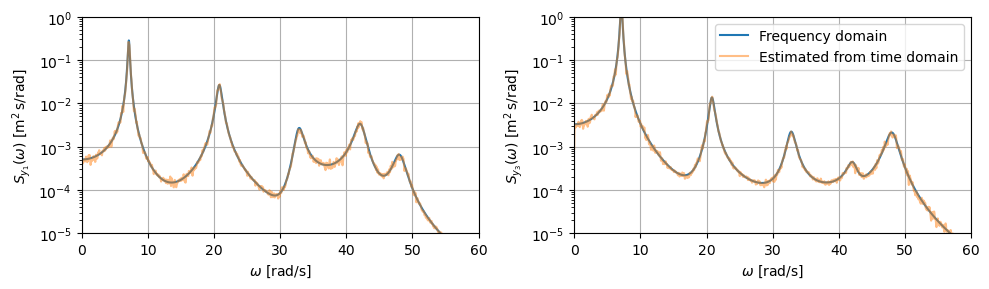

In [11]:
ndivisions = 20 # Sets segment duration to approximately T/20
nwindow = len(t)//ndivisions # Length of window/segment
noverlap = nwindow//2

nfft_pow2 = 2**int(np.ceil(np.log2(nwindow))) # Next power of 2 for zero padding

# Call welch from scipy signal processing
f_welch, Sy_1_tmp = spsi.welch(y[0,:], fs=1/dt, window='hann', nperseg=nwindow, noverlap=noverlap, nfft=nfft_pow2, detrend='constant', return_onesided=True, scaling='density', axis=- 1, average='mean')

omega_welch = f_welch*2*np.pi # Transform to rad/s
Sy_1 = Sy_1_tmp/(2*np.pi) # Transform to rad/s

# Call welch from scipy signal processing
_, Sy_3_tmp = spsi.welch(y[2,:], fs=1/dt, window='hann', nperseg=nwindow, noverlap=noverlap, nfft=nfft_pow2, detrend='constant', return_onesided=True, scaling='density', axis=- 1, average='mean')
Sy_3 = Sy_3_tmp/(2*np.pi) # Transform to rad/s

fig, axs = plt.subplots(1,2,figsize=(10,3))

axs[0].plot(omega_axis,np.real(Sy[0,0]),label='Frequency domain')
axs[0].plot(omega_welch,Sy_1,label = 'Estimated from time domain',alpha=0.5)
axs[0].set_xlim(0,60)
axs[0].grid()
axs[0].set_yscale('log')
axs[0].set_ylim(1e-5,1e0)
axs[0].set_xlabel(r'$\omega$ [rad/s]')
axs[0].set_ylabel(r'$S_{y_1}(\omega)$ [$\mathrm{m^2\,s/rad}$]')

axs[1].plot(omega_axis,np.real(Sy[2,2]),label='Frequency domain')
axs[1].plot(omega_welch,Sy_3,label = 'Estimated from time domain',alpha=0.5)
axs[1].set_xlim(0,60)
axs[1].grid()
axs[1].set_yscale('log')
axs[1].set_ylim(1e-5,1e0)
axs[1].set_xlabel(r'$\omega$ [rad/s]')
axs[1].set_ylabel(r'$S_{y_3}(\omega)$ [$\mathrm{m^2\,s/rad}$]')

axs[1].legend()

plt.tight_layout()

About 20 divisions is a reasonable starting point: segments are approximately 90 s long, with 50% overlap giving about 39 windows. Longer segments resolve narrow peaks better; more, shorter segments reduce variability but broaden peaks. Zero-padding gives a finer plotted frequency grid, not better spectral resolution. Segment length, overlap and FFT length are passed as integers.


**e**)

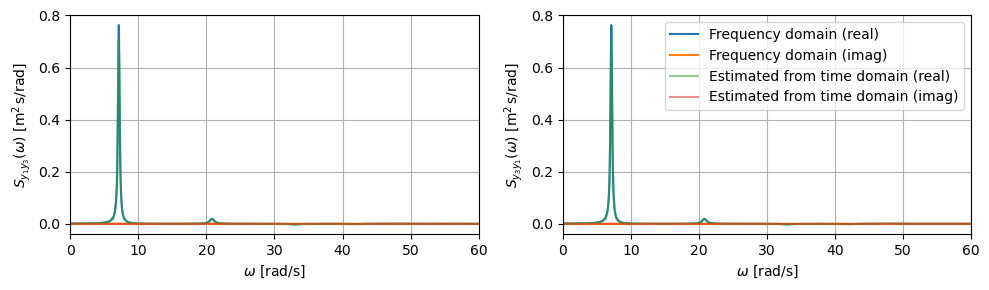

In [12]:
# Call welch from scipy signal processing
f, Sy_13_tmp = spsi.csd(y[0,:], y[2,:], fs=1/dt, window='hann', nperseg=nwindow, noverlap=noverlap, nfft=nfft_pow2, detrend='constant', return_onesided=True, scaling='density', axis=- 1, average='mean')
f, Sy_31_tmp = spsi.csd(y[2,:], y[0,:], fs=1/dt, window='hann', nperseg=nwindow, noverlap=noverlap, nfft=nfft_pow2, detrend='constant', return_onesided=True, scaling='density', axis=- 1, average='mean')

Sy_13 = Sy_13_tmp/(2*np.pi) # Transform to rad/s
Sy_31 = Sy_31_tmp/(2*np.pi) # Transform to rad/s


fig, axs = plt.subplots(1,2,figsize=(10,3))

axs[0].plot(omega_axis,np.real(Sy[0,2]),label='Frequency domain (real)')
axs[0].plot(omega_axis,np.imag(Sy[0,2]),label='Frequency domain (imag)')
axs[0].plot(omega_welch,np.real(Sy_13),label = 'Estimated from time domain (real)',alpha=0.5)
axs[0].plot(omega_welch,np.imag(Sy_31),label = 'Estimated from time domain (imag)',alpha=0.5)
axs[0].set_xlim(0,60)
axs[0].grid()
axs[0].set_xlabel(r'$\omega$ [rad/s]')
axs[0].set_ylabel(r'$S_{y_1 y_3}(\omega)$ [$\mathrm{m^2\,s/rad}$]')

axs[1].plot(omega_axis,np.real(Sy[2,0]),label='Frequency domain (real)')
axs[1].plot(omega_axis,np.imag(Sy[2,0]),label='Frequency domain (imag)')
axs[1].plot(omega_welch,np.real(Sy_31),label = 'Estimated from time domain (real)',alpha=0.5)
axs[1].plot(omega_welch,np.imag(Sy_31),label = 'Estimated from time domain (imag)',alpha=0.5)
axs[1].set_xlim(0,60)
axs[1].grid()
axs[1].set_xlabel(r'$\omega$ [rad/s]')
axs[1].set_ylabel(r'$S_{y_3 y_1}(\omega)$ [$\mathrm{m^2\,s/rad}$]')

axs[1].legend()

plt.tight_layout()



We have plotted both $S_{y_1 y_3}$ and $S_{y_3 y_1}$. As expected, the real part is the same for both. Although the imaginary part here is almost zero, it would be possible to confirm that the imaginary parts in the two subplots are equal but with opposite signs. 

The conclusions here on the number of windows are largely the same as the previous question.